# Choosing a pulse pattern

More pulses per period deliver more neutrons, but the gain in measurement
time depends on how the spectra of the pulses are kept apart or analysed
together. This notebook compares, for N pulses of 200 µs per 50 ms period:

* one longer pulse of N × 200 µs,
* N equally spaced pulses, with and without an ideal bandwidth chopper,
* N pulses at random times and a maximum-length (pseudorandom) sequence,
* N pulses at times optimised for the edge position (strain).

All numbers are Cramér–Rao bounds of the Rietveld fit, which reaches them.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import nbragg
import frame_overlap as fo

# the material, as in nbragg: 2 cm of alpha-iron
xs = nbragg.CrossSection(materials={"iron": {"mat": "Fe_sg229_Iron-alpha.ncmat"}})
model = nbragg.TransmissionModel(xs, response="jorgensen_inv", tof_length=9.0, vary_response=False)
model.params["thickness"].set(value=2.0)     # cm
model.params["α0"].set(value=3000.0)         # moderator response (rise), close to a water moderator
model.params["β0"].set(value=50.0)           # moderator response (decay)
sample = fo.Sample(model, free=["thickness", "strain"])

# the instrument: 9 m flight path, 50 ms period, 10 us bins, a thermal moderator
grid = fo.TimeGrid(flight_path=9.0, frequency=20.0, bin_width=10e-6)
beam = fo.OpenBeam.maxwellian(grid, flux=5e6, area=0.03)
hours = 8

In [2]:
exp = fo.Experiment(sample, beam, fo.Pattern.single(200e-6), time=hours * 3600)
LAM_PER_S = grid.wavelength_at(1.0)        # Angstrom per second of flight

def bandwidth_beam(n, lo=0.97, hi=5.25, last_edge=4.55):
    """Ideal bandwidth chopper: each pulse keeps a band that fits between pulses."""
    width = (grid.period / n - 250e-6) * LAM_PER_S
    if lo + width >= hi:
        return beam.with_band(lo, hi)
    top = max(lo + width, last_edge)
    return beam.with_band(max(lo, top - width), top)

ref = exp.precision().set_index("parameter").sigma          # one 200 us pulse, no chopper

def R(e):
    """time-reduction factor of a design against one 200 us pulse per period"""
    return dict((ref / e.precision().set_index("parameter").sigma) ** 2)

rows = []
for n in [1, 2, 4, 8]:
    designs = {"one longer pulse": fo.Pattern([0.0], n * 200e-6),
               "equal, no chopper": fo.Pattern.equal(n, period=grid.period),
               "random times": fo.Pattern.random(n, period=grid.period, seed=n)}
    if n in (2, 4, 8):
        designs["maximum-length sequence"] = fo.Pattern.maximum_length({2: 2, 4: 3, 8: 4}[n], period=grid.period)
    for name, p in designs.items():
        rows.append(dict(N=n, design=name, **R(exp.with_pattern(p))))
    eb = fo.Experiment(sample, bandwidth_beam(n), fo.Pattern.equal(n, period=grid.period), time=hours * 3600)
    rows.append(dict(N=n, design="equal, bandwidth chopper", **R(eb)))
    if n > 1:
        best = fo.optimise_pattern(exp, n, target="strain", n_restarts=2, n_steps=400, seed=n)
        rows.append(dict(N=n, design="optimised for strain", **R(exp.with_pattern(best))))
import pandas as pd
table = pd.DataFrame(rows)
table.pivot(index="N", columns="design", values="strain").round(2)

design,"equal, bandwidth chopper","equal, no chopper",maximum-length sequence,one longer pulse,optimised for strain,random times
N,,,,,,
1,1.00,1.00,NaN,1.00,NaN,1.00
2,2.00,2.00,1.99,1.02,2.00,1.99
4,4.00,3.38,2.57,0.92,3.91,1.82
8,7.27,1.03,2.69,0.73,4.35,2.52


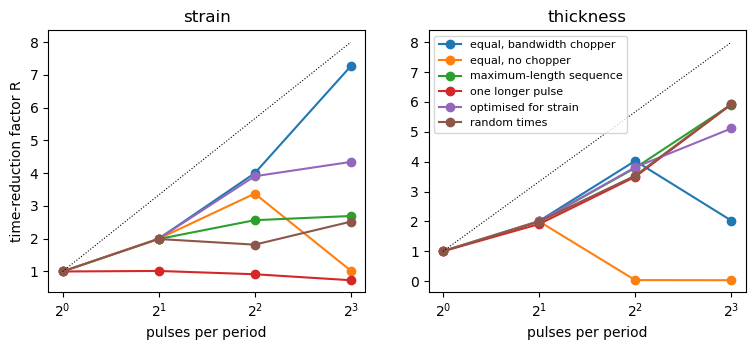

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharex=True)
for ax, par in zip(axes, ["strain", "thickness"]):
    for name, g in table.groupby("design"):
        ax.plot(g.N, g[par], "o-", label=name)
    ax.plot([1, 8], [1, 8], "k:", lw=0.8)
    ax.set_xscale("log", base=2); ax.set_xlabel("pulses per period"); ax.set_title(par)
axes[0].set_ylabel("time-reduction factor R")
axes[1].legend(fontsize=8)
plt.show()

With a bandwidth chopper the pulses do not overlap and R grows with N as
long as the band needed for the edges fits between pulses. Without it, the
spectra overlap; optimised pulse times keep the thermal peak of each pulse
away from the edges of the others and still give a gain of about four for the
strain. A longer pulse helps the thickness but not the edge position.